# Topic 5: Confidence Intervals
**BIT 4131** | Dataset: UCI Student Performance (Portuguese course, n = 649)

---
## 1. Theoretical explanation
- A **point estimate** (e.g. the sample mean) is a single best guess for an unknown parameter. It carries sampling uncertainty (Topic 4).
- A **confidence interval (CI)** gives a range of plausible values for the parameter. A **95% CI** means: if we repeated the sampling many times and built an interval each time, about 95% of those intervals would contain the true parameter.
- It does **not** mean there is a 95% probability that the true value lies inside one particular computed interval.
- For a mean with unknown population standard deviation we use the **t-distribution**; for a proportion we use a normal approximation (Wald) or the better-behaved **Wilson** interval.
- In this topic the 649 students are treated as a **sample** from the wider population of students taking this course.

---
## 2. Mathematical formulation
**Mean (unknown $\sigma$):**
$$\bar x \;\pm\; t_{\alpha/2,\,n-1}\,\frac{s}{\sqrt n}$$

**Proportion:** with $\hat p = x/n$,
$$\text{Wald: } \hat p \pm z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}
\qquad
\text{Wilson: } \frac{\hat p+\frac{z^2}{2n}\;\pm\; z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}{1+\frac{z^2}{n}}$$

**Margin of error:** $E = t_{\alpha/2,n-1}\,s/\sqrt n$. To reach a target margin $E$ we need roughly $n \approx (z\,s/E)^2$.

---
## 3. Worked example
Ten sample grades: `10, 12, 9, 14, 11, 13, 15, 8, 12, 11`. Build a 95% CI for the mean by hand.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

x = np.array([10, 12, 9, 14, 11, 13, 15, 8, 12, 11])
n = len(x); xbar = x.mean(); s = x.std(ddof=1); se = s / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n - 1)
lo, hi = xbar - t_crit * se, xbar + t_crit * se

print(f"n = {n}, mean = {xbar:.3f}, s = {s:.3f}, SE = s/sqrt(n) = {se:.3f}")
print(f"t critical (df = {n-1}, 97.5%) = {t_crit:.3f}")
print(f"95% CI = {xbar:.3f} +/- {t_crit:.3f} x {se:.3f} = ({lo:.3f}, {hi:.3f})")

# cross-check with scipy
print("scipy check:", tuple(round(float(v), 3) for v in stats.t.interval(0.95, n - 1, loc=xbar, scale=se)))

n = 10, mean = 11.500, s = 2.173, SE = s/sqrt(n) = 0.687
t critical (df = 9, 97.5%) = 2.262
95% CI = 11.500 +/- 2.262 x 0.687 = (9.945, 13.055)
scipy check: (9.945, 13.055)


---
## 4. Dataset analysis

In [2]:
df = pd.read_csv("../data/student-por.csv", sep=";")
g3 = df["G3"]
n = len(g3); xbar = g3.mean(); s = g3.std(ddof=1); se = s / np.sqrt(n)

def mean_ci(v, conf=0.95):
    v = np.asarray(v, float); n = len(v); se = v.std(ddof=1) / np.sqrt(n)
    return v.mean(), *stats.t.interval(conf, n - 1, loc=v.mean(), scale=se), se

# (a) CI for the mean G3, at three confidence levels
rows = []
for conf in (0.90, 0.95, 0.99):
    m, lo, hi, se_ = mean_ci(g3, conf)
    rows.append({"confidence": f"{conf:.0%}", "estimate": m, "lower": lo, "upper": hi, "margin of error": (hi - lo) / 2})
print("Mean final grade G3 (n = %d, SE = %.4f)" % (n, se))
print(pd.DataFrame(rows).round(3).to_string(index=False))

# (b) CI for the mean G3 by school
print("\nBy school (95% t-interval):")
for sch, grp in df.groupby("school"):
    m, lo, hi, _ = mean_ci(grp["G3"])
    print(f"  {sch}: n = {len(grp):3d}, mean = {m:.3f}, CI = ({lo:.3f}, {hi:.3f})")

Mean final grade G3 (n = 649, SE = 0.1268)
confidence  estimate  lower  upper  margin of error
       90%    11.906 11.697 12.115            0.209
       95%    11.906 11.657 12.155            0.249
       99%    11.906 11.578 12.234            0.328

By school (95% t-interval):
  GP: n = 423, mean = 12.577, CI = (12.326, 12.828)
  MS: n = 226, mean = 10.650, CI = (10.148, 11.153)


In [3]:
# (c) CI for the pass rate (G3 >= 10): Wald vs Wilson
x_pass = int((g3 >= 10).sum()); p_hat = x_pass / n; z = stats.norm.ppf(0.975)
wald = (p_hat - z * np.sqrt(p_hat * (1 - p_hat) / n), p_hat + z * np.sqrt(p_hat * (1 - p_hat) / n))
centre = (p_hat + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
wilson = (centre - half, centre + half)
print(f"Pass rate: {x_pass}/{n} = {p_hat:.4f}")
print(f"  Wald   95% CI: ({wald[0]:.4f}, {wald[1]:.4f})")
print(f"  Wilson 95% CI: ({wilson[0]:.4f}, {wilson[1]:.4f})")

Pass rate: 549/649 = 0.8459
  Wald   95% CI: (0.8181, 0.8737)
  Wilson 95% CI: (0.8161, 0.8717)


955 of 1000 intervals (n = 30) contain the true mean 11.906: coverage = 95.5%


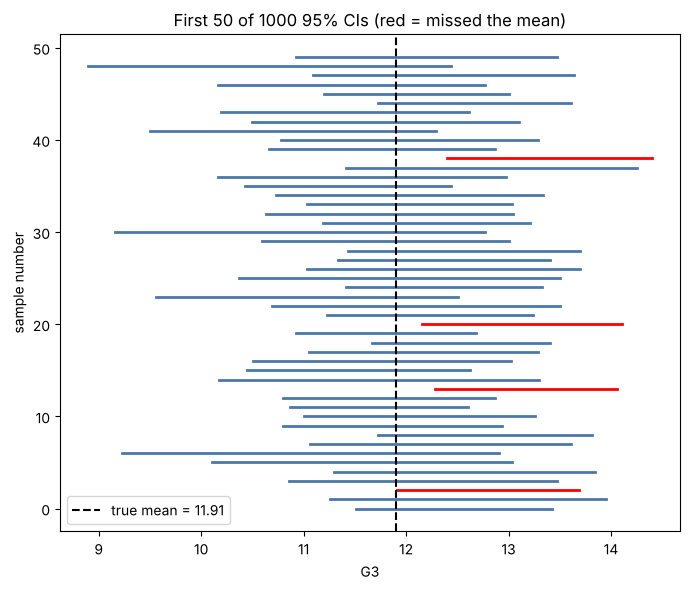

In [4]:
# (d) What does "95% confidence" mean? Repeat the sampling many times and count coverage.
rng = np.random.default_rng(4131)
true_mu = g3.mean()          # treat the 649 students as the population here
reps, n_s = 1000, 30
covered, intervals = 0, []
for _ in range(reps):
    samp = rng.choice(g3.to_numpy(), size=n_s, replace=False)
    m, lo, hi, _ = mean_ci(samp)
    intervals.append((lo, hi)); covered += (lo <= true_mu <= hi)
print(f"{covered} of {reps} intervals (n = {n_s}) contain the true mean {true_mu:.3f}: coverage = {covered/reps:.1%}")

fig, ax = plt.subplots(figsize=(7, 6))
for i, (lo, hi) in enumerate(intervals[:50]):
    ax.plot([lo, hi], [i, i], color="#4C78A8" if lo <= true_mu <= hi else "red", lw=2)
ax.axvline(true_mu, color="black", ls="--", label=f"true mean = {true_mu:.2f}")
ax.set(xlabel="G3", ylabel="sample number", title="First 50 of 1000 95% CIs (red = missed the mean)")
ax.legend(); plt.tight_layout(); plt.savefig("figures/t05_ci_coverage.png", dpi=130); plt.show()

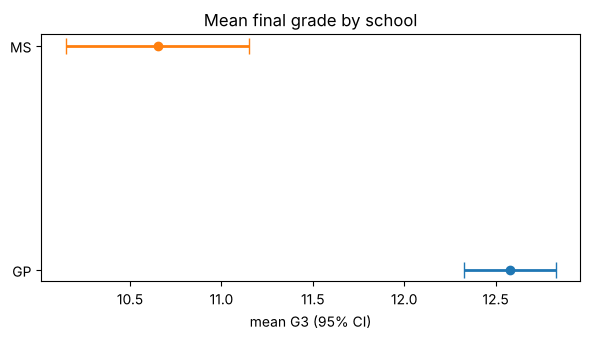

In [5]:
# (e) Point estimate and CI by school, plotted
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, (sch, grp) in enumerate(df.groupby("school")):
    m, lo, hi, _ = mean_ci(grp["G3"])
    ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt="o", capsize=6, lw=2)
ax.set_yticks([0, 1]); ax.set_yticklabels(["GP", "MS"]); ax.set(xlabel="mean G3 (95% CI)", title="Mean final grade by school")
plt.tight_layout(); plt.savefig("figures/t05_ci_by_school.png", dpi=130); plt.show()

---
## 5. Expected statistical output
Each point estimate with its 95% confidence interval and margin of error. The coverage simulation and the by-school interval plot are saved in `figures/`.

In [6]:
gpv = df.loc[df.school == "GP", "G3"]; msv = df.loc[df.school == "MS", "G3"]
rows = []
for label, v in [("Mean G3, all students", g3), ("Mean G3, school GP", gpv), ("Mean G3, school MS", msv)]:
    m, lo, hi, _ = mean_ci(v)
    rows.append((label, len(v), f"{m:.2f}", f"({lo:.2f}, {hi:.2f})", f"{(hi - lo) / 2:.2f}"))
rows.append(("Pass rate (G3 >= 10), Wilson", n, f"{p_hat:.3f}", f"({wilson[0]:.3f}, {wilson[1]:.3f})", f"{(wilson[1] - wilson[0]) / 2:.3f}"))
print(pd.DataFrame(rows, columns=["Quantity", "n", "Point estimate", "95% CI", "Margin of error"]).to_string(index=False))

                    Quantity   n Point estimate         95% CI Margin of error
       Mean G3, all students 649          11.91 (11.66, 12.16)            0.25
          Mean G3, school GP 423          12.58 (12.33, 12.83)            0.25
          Mean G3, school MS 226          10.65 (10.15, 11.15)            0.50
Pass rate (G3 >= 10), Wilson 649          0.846 (0.816, 0.872)           0.028


---
## 6. Interpretation of results

In [7]:
m95, lo95, hi95, _ = mean_ci(g3)
gp = mean_ci(df.loc[df.school == "GP", "G3"]); ms = mean_ci(df.loc[df.school == "MS", "G3"])
print(f"1. The sample mean G3 is {m95:.2f}; we are 95% confident the true mean lies between {lo95:.2f} and {hi95:.2f} (margin of error {(hi95-lo95)/2:.2f} points).")
print("2. Higher confidence gives a wider interval (90% < 95% < 99%): more certainty costs precision.")
print(f"3. School intervals do not overlap: GP ({gp[1]:.2f}, {gp[2]:.2f}) vs MS ({ms[1]:.2f}, {ms[2]:.2f}). "
      "This is evidence of a real gap, which Topic 6 tests formally. MS is wider because it has fewer students and more spread.")
print(f"4. About {p_hat:.0%} of students pass (G3 >= 10); the Wilson interval is ({wilson[0]:.3f}, {wilson[1]:.3f}). "
      "Wald and Wilson agree closely here because n is large and p is not extreme.")
print(f"5. Coverage check: {covered/reps:.1%} of the simulated 95% intervals captured the true mean, close to the nominal 95%.")

1. The sample mean G3 is 11.91; we are 95% confident the true mean lies between 11.66 and 12.16 (margin of error 0.25 points).
2. Higher confidence gives a wider interval (90% < 95% < 99%): more certainty costs precision.
3. School intervals do not overlap: GP (12.33, 12.83) vs MS (10.15, 11.15). This is evidence of a real gap, which Topic 6 tests formally. MS is wider because it has fewer students and more spread.
4. About 85% of students pass (G3 >= 10); the Wilson interval is (0.816, 0.872). Wald and Wilson agree closely here because n is large and p is not extreme.
5. Coverage check: 95.5% of the simulated 95% intervals captured the true mean, close to the nominal 95%.


**Take-aways**
- Report an estimate **with** its uncertainty: "mean G3 is about 11.9, 95% CI (11.66, 12.16)".
- Interval width depends on the confidence level, the variability ($s$) and the sample size ($1/\sqrt n$).
- Non-overlapping CIs suggest a difference but are not a formal test; that is Topic 6.